In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [17]:
# loading cleaned data 

df = pd.read_csv('../Dataset/wine_quality_cleaned.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5320 entries, 0 to 5319
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         5320 non-null   float64
 1   volatile_acidity      5320 non-null   float64
 2   citric_acid           5320 non-null   float64
 3   residual_sugar        5320 non-null   float64
 4   chlorides             5320 non-null   float64
 5   free_sulfur_dioxide   5320 non-null   float64
 6   total_sulfur_dioxide  5320 non-null   float64
 7   density               5320 non-null   float64
 8   pH                    5320 non-null   float64
 9   sulphates             5320 non-null   float64
 10  alcohol               5320 non-null   float64
 11  quality               5320 non-null   int64  
 12  color                 5320 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 540.4 KB


In [18]:
# splitting data into X and y 

X = df.drop('quality', axis=1)
y = df['quality']

In [19]:
# encoding color column with labelencoder

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
X['color'] = le.fit_transform(X['color'])

X.head(5)

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,0


In [20]:
# splititng data into training and test set

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=True, test_size=0.2, random_state=42)

In [2]:
# importing featured engineer train and test data

X_train_fe = pd.read_csv('../Dataset/X_train_fe.csv')
X_test_fe = pd.read_csv('../Dataset/X_test_fe.csv')

In [6]:
print('Number of Features:', X_train_fe.shape[1])
print()

print(X_train_fe.columns.to_list())

Number of Features: 20

['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'color', 'total_acidity', 'acidity_ratio', 'extra_sulphur_dioxide', 'sulphur_dioxide_ratio', 'sugar_alcohol_ratio', 'density_alcohol_ratio', 'alcohol_sulphates', 'alcohol_acidity']


In [8]:
# checking for constant features

constant_features = [
    col for col in X_train_fe.columns
    if X_train_fe[col].nunique() == 1
]

print("Constant Features:", constant_features)

Constant Features: []


In [10]:
# checking for highly related features

corr_matrix = X_train_fe.corr().abs()
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape),
            k=1).astype(bool)
)

high_corr_features = [
    column for column in upper.columns
    if any(upper[column] > 0.90)
]
print("High Correlated Features:", high_corr_features)

High Correlated Features: ['total_acidity', 'extra_sulphur_dioxide', 'sugar_alcohol_ratio', 'density_alcohol_ratio', 'alcohol_sulphates']


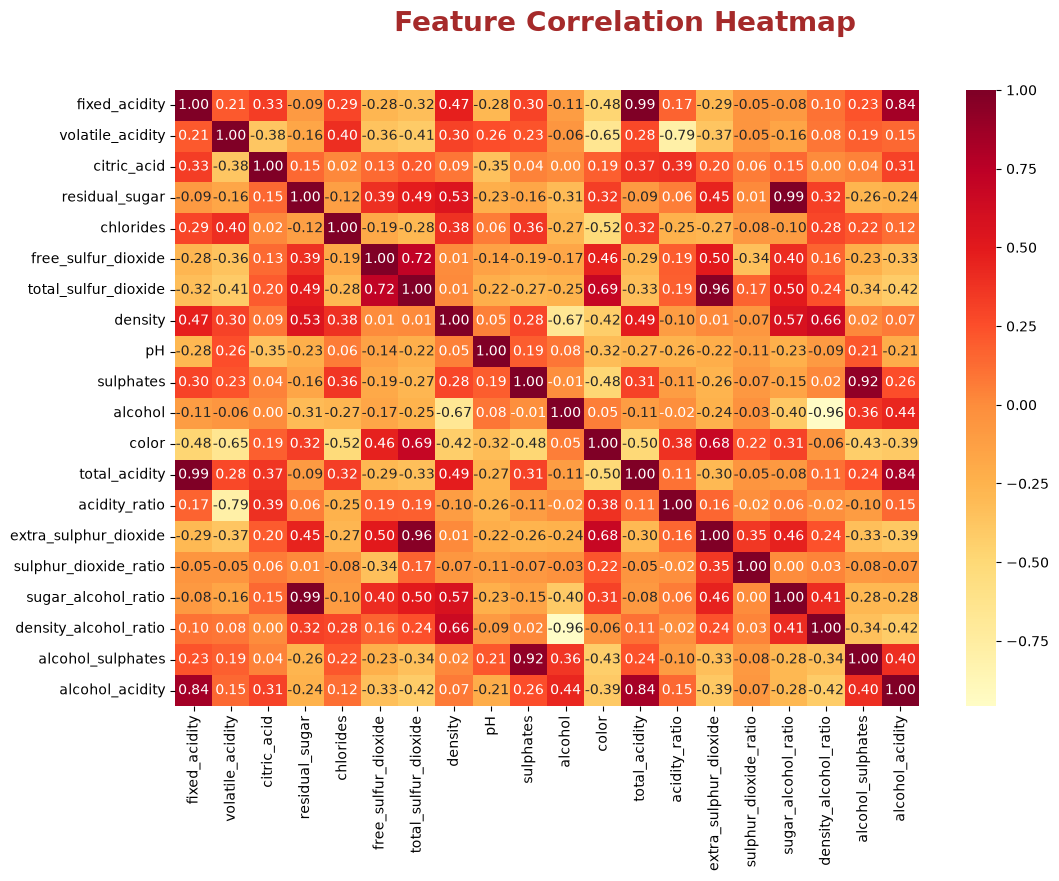

In [14]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    X_train_fe.corr(),
    annot=True,
    cmap='YlOrRd',
    center=0,
    fmt='.2f'
)

plt.suptitle(
    'Feature Correlation Heatmap',
    color='brown',
    fontsize=20,
    fontweight='bold'
)

plt.show()

In [29]:
# dropping highly correlated features

columns_to_drop = ['total_acidity', 'extra_sulphur_dioxide', 'sugar_alcohol_ratio', 'density_alcohol_ratio']
X_train_fs  = X_train_fe.drop(columns_to_drop, axis=1)
X_test_fs  = X_test_fe .drop(columns_to_drop, axis=1)

print(X_train_fs.columns.to_list())

['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'color', 'acidity_ratio', 'sulphur_dioxide_ratio', 'alcohol_sulphates', 'alcohol_acidity']


In [21]:
# check target correlations

corr_with_target = pd.concat([X_train_fe, y_train], axis=1).corr()['quality'].sort_values(ascending=False)
print(corr_with_target)

quality                  1.000000
citric_acid              0.038318
alcohol_acidity          0.036666
alcohol                  0.032782
sulphur_dioxide_ratio    0.027515
extra_sulphur_dioxide    0.027143
total_sulfur_dioxide     0.026803
total_acidity            0.024627
fixed_acidity            0.022518
residual_sugar           0.021926
color                    0.019922
sugar_alcohol_ratio      0.017995
free_sulfur_dioxide      0.015780
alcohol_sulphates        0.007073
chlorides                0.005008
volatile_acidity        -0.003430
density                 -0.004488
sulphates               -0.005499
acidity_ratio           -0.013001
density_alcohol_ratio   -0.029204
pH                      -0.044964
Name: quality, dtype: float64


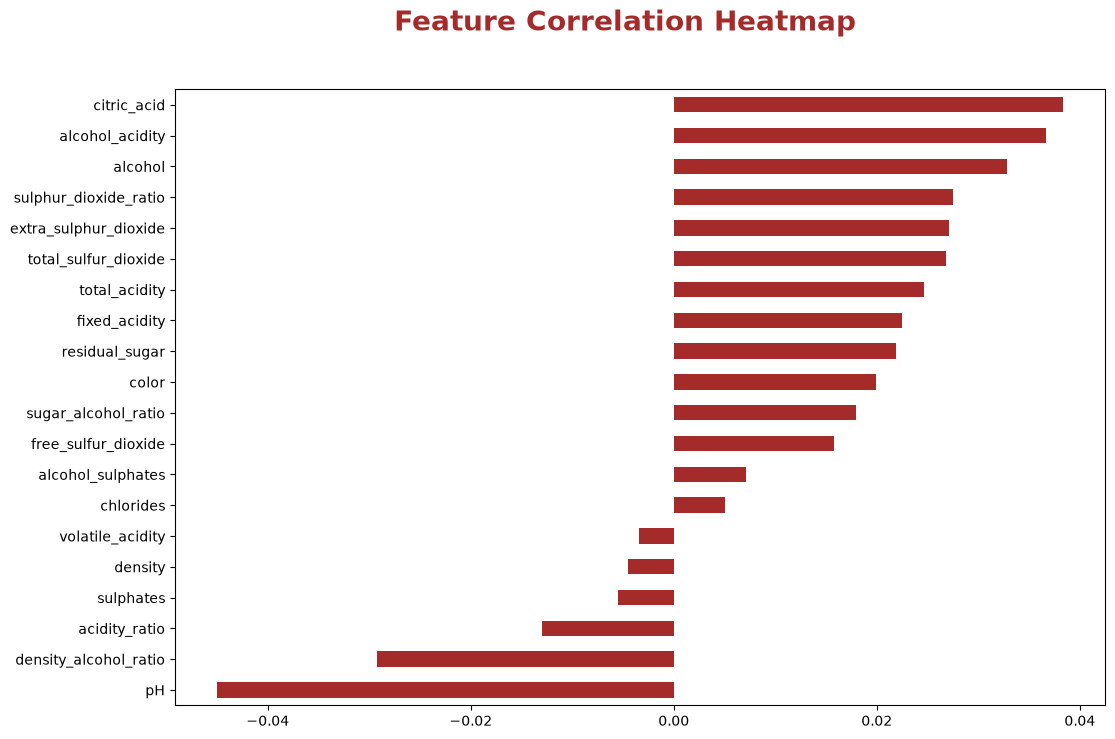

In [22]:
#  target correlations visualization

plt.figure(figsize=(12, 8))

corr_with_target.drop('quality').sort_values().plot(kind='barh', color='brown')

plt.suptitle(
    'Feature Correlation Heatmap',
    color='brown',
    fontsize=20,
    fontweight='bold'
)

plt.show()

In [23]:
# build a single feature selection model

from sklearn.ensemble import RandomForestRegressor

fs_model = RandomForestRegressor(random_state=42)
fs_model.fit(X_train_fs, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [24]:
# getting the prediction

fs_model_prediction = fs_model.predict(X_test_fs)

In [27]:
# testing the feature selection model

from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

fs_result = pd.DataFrame({
    'R² Score': [r2_score( y_test, fs_model_prediction)],
    'MAE Score': [mean_absolute_error( y_test, fs_model_prediction)],
    'RMSE Score': [ root_mean_squared_error( y_test, fs_model_prediction)]
})
fs_result

,R² Score,MAE Score,RMSE Score
0,0.40346,0.516175,0.669717


In [28]:
# comparing the baseline and feature selection model

bs_result = pd.read_csv(
    '../Report/Results/baseline_results.csv',
    index_col=0
)

comparison_df = pd.concat(
    [bs_result, fs_result],
    ignore_index=True
)

comparison_df

,R² Score,MAE Score,RMSE Score
0,0.41380,0.508177,0.663888
1,0.40346,0.516175,0.669717


In [30]:
# testing the feature selection model with cross validation

from sklearn.model_selection import cross_validate

rf = RandomForestRegressor(random_state=42)

cv_score = cross_validate(
    rf,
    X_train_fs,
    y_train,
    cv=5,
    scoring={
        'r2': 'r2',
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error'
    }   
)

In [31]:
# getting the score of feature selection model with cross validation

cv_result = pd.DataFrame({
    'R² Score': [cv_score['test_r2'].mean()],
    'MAE Score': [-cv_score['test_mae'].mean()],
    'RMSE Score': [-cv_score['test_rmse'].mean()]
})

cv_result

,R² Score,MAE Score,RMSE Score
0,0.3695,0.538892,0.699588


In [33]:
# comparing baseline and feature model along with cross validation

results_comparison = pd.concat(
    [bs_result, fs_result, cv_result],
    ignore_index=True
)

results_comparison

,R² Score,MAE Score,RMSE Score
0,0.41380,0.508177,0.663888
1,0.40346,0.516175,0.669717
2,0.36950,0.538892,0.699588


In [36]:
# check feature importance of the model 

rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

rf.fit(X_train_fe, y_train)

importance_df = pd.DataFrame({
    'Feature': X_train_fe.columns,
    'Importance': rf.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
)

print(importance_df)

                  Feature  Importance
10                alcohol    0.245068
13          acidity_ratio    0.085458
15  sulphur_dioxide_ratio    0.071905
18      alcohol_sulphates    0.058907
1        volatile_acidity    0.057614
5     free_sulfur_dioxide    0.056680
8                      pH    0.052094
4               chlorides    0.044933
2             citric_acid    0.041312
7                 density    0.038163
6    total_sulfur_dioxide    0.037843
14  extra_sulphur_dioxide    0.034012
9               sulphates    0.032897
19        alcohol_acidity    0.032553
12          total_acidity    0.031716
3          residual_sugar    0.031327
16    sugar_alcohol_ratio    0.026779
0           fixed_acidity    0.017361
17  density_alcohol_ratio    0.002698
11                  color    0.000680


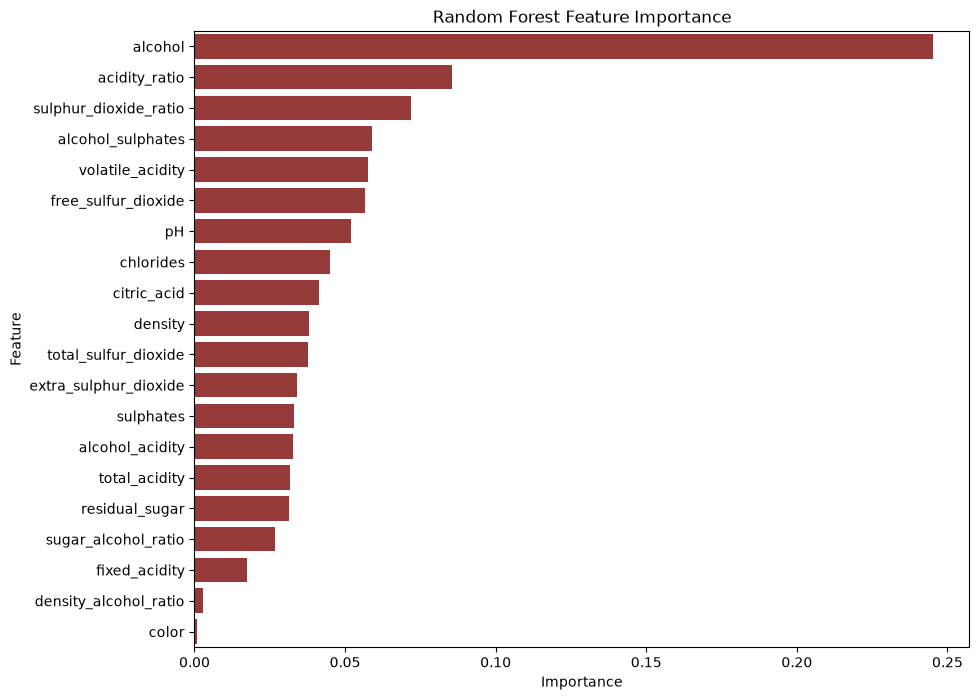

In [37]:
# Add feature importance visualization

plt.figure(figsize=(10,8))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature',
    color='brown'
)

plt.title('Random Forest Feature Importance')
plt.show()